# Extract all Alphacoronavirus

Based on the ntblast seach done as of 2025-09-11

In [2]:
import pandas as pd
from Bio import SeqIO, Entrez
from Bio.Seq import Seq 
import matplotlib as mpl
from matplotlib.font_manager import FontProperties
mpl.rcParams['svg.fonttype'] = 'none'
# Path to your Arial.ttf file
arial_font_path = '/Users/skawakubo/python/fonts/Arial.ttf'
# Create a FontProperties object for the Arial font
arial_font = FontProperties(fname=arial_font_path)
mpl.rcParams['font.family'] = arial_font.get_name()
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import time
import subprocess

Entrez.email = 'skawakubo@g.ecc.u-tokyo.ac.jp'

In [2]:
# stem_dir_path = '/Users/skawakubo/github_repos/FCoV-evolution'

In [17]:
def fasta_to_dataframe(fasta_file):
    ids = []
    sequences = []
    for record in SeqIO.parse(fasta_file, "fasta"):
        ids.append(record.id)
        sequences.append(str(record.seq))

    df = pd.DataFrame({
        "ID": ids,
        "seq": sequences
    })
    return df

In [4]:
# Read the fasta file
AlphaCoV_seq_path = 'FCoV_CCoV_FCoV23_TGEV_FRCoV_MCoV_full_nt_250818.fasta'
AlphaCoV_seq = fasta_to_dataframe(AlphaCoV_seq_path)
AlphaCoV_seq.rename(columns={"ID": "Accession"}, inplace=True)
AlphaCoV_seq

,Accession,seq
0,NC_038861.1,ACTTTTAAAGTAAAGTGAGTGTAGCGTGGCTATATCTCTTCTTTTA...
1,PV096984.1,ACTTTTAAAGTAAAGTGAGTGTAGCGTGGCTATATCTCTTCTTTTA...
2,PQ856105.1,TCCAGTAAAAAGTAGTGTAGCGTGGCTGTATCTCTTCTTTTACTTT...
3,PQ821888.1,TCCAGTAAAAAGTAGTGTAGCGTGGCTGTATCTCTTCTTTTACTTT...
4,PQ189446.1,ACTTTTAAAGTAAAGTGAGTGTAGCGTGGCTATATCTCTTCTTTTA...
...,...,...
344,775024S_S3_L001,gacaccaactcgaactaaacgaaatatttgtctctctatgaaacca...
345,771819S_S4_L001,cggacaccaactcgaactaaacgaaatatttgtctctctatgaaac...
346,PP254212.1,tgtggcgtggctataactctgcttgkngtttaacctgccttgtgct...
347,PP254214.1,tttactttaacctgccttgtgctagatttgtcttcggacaccaact...


In [5]:
AlphaCoV_seq['N_count'] = AlphaCoV_seq['seq'].apply(lambda x: x.count('N') + x.count('n'))
AlphaCoV_seq

,Accession,seq,N_count
0,NC_038861.1,ACTTTTAAAGTAAAGTGAGTGTAGCGTGGCTATATCTCTTCTTTTA...,0
1,PV096984.1,ACTTTTAAAGTAAAGTGAGTGTAGCGTGGCTATATCTCTTCTTTTA...,0
2,PQ856105.1,TCCAGTAAAAAGTAGTGTAGCGTGGCTGTATCTCTTCTTTTACTTT...,0
3,PQ821888.1,TCCAGTAAAAAGTAGTGTAGCGTGGCTGTATCTCTTCTTTTACTTT...,0
4,PQ189446.1,ACTTTTAAAGTAAAGTGAGTGTAGCGTGGCTATATCTCTTCTTTTA...,0
...,...,...,...
344,775024S_S3_L001,gacaccaactcgaactaaacgaaatatttgtctctctatgaaacca...,0
345,771819S_S4_L001,cggacaccaactcgaactaaacgaaatatttgtctctctatgaaac...,0
346,PP254212.1,tgtggcgtggctataactctgcttgkngtttaacctgccttgtgct...,4633
347,PP254214.1,tttactttaacctgccttgtgctagatttgtcttcggacaccaact...,4492


In [6]:
AlphaCoV_seq_cleaned = AlphaCoV_seq[AlphaCoV_seq['N_count'] == 0]
AlphaCoV_seq_cleaned    

,Accession,seq,N_count
0,NC_038861.1,ACTTTTAAAGTAAAGTGAGTGTAGCGTGGCTATATCTCTTCTTTTA...,0
1,PV096984.1,ACTTTTAAAGTAAAGTGAGTGTAGCGTGGCTATATCTCTTCTTTTA...,0
2,PQ856105.1,TCCAGTAAAAAGTAGTGTAGCGTGGCTGTATCTCTTCTTTTACTTT...,0
3,PQ821888.1,TCCAGTAAAAAGTAGTGTAGCGTGGCTGTATCTCTTCTTTTACTTT...,0
4,PQ189446.1,ACTTTTAAAGTAAAGTGAGTGTAGCGTGGCTATATCTCTTCTTTTA...,0
...,...,...,...
340,KP143510.1,gggttccgtccctgtttggtaagtcgtctagtattagctgcggcgg...,0
341,KP143511.1,gggttccgtccctgtttggtaagtcgtctagtattagctgcggcgg...,0
343,DQ848678.1,acttttaaagtaaagtgagtgtagcgtggctataactcttcttttc...,0
344,775024S_S3_L001,gacaccaactcgaactaaacgaaatatttgtctctctatgaaacca...,0


In [ ]:
# with open('FCoV_CCoV_FCoV23_TGEV_FRCoV_MCoV_full_nt_250818_cleaned.fasta', 'w') as f:
#     for index, row in AlphaCoV_seq_cleaned.iterrows():
#         f.write(f">{row['Accession']}\n{row['seq']}\n")

In [ ]:
# # run CD-HIT
# ! cd-hit -i FCoV_CCoV_FCoV23_TGEV_FRCoV_MCoV_full_nt_250818_cleaned.fasta -o FCoV_CCoV_FCoV23_TGEV_FRCoV_MCoV_full_nt_250818_cleaned_clu90.fasta -c 0.90 -T 4

Program: CD-HIT, V4.8.1, Apr 07 2021, 02:35:32
Command: cd-hit -i
         FCoV_CCoV_FCoV23_TGEV_FRCoV_MCoV_full_nt_250818_cleaned.fasta
         -o
         FCoV_CCoV_FCoV23_TGEV_FRCoV_MCoV_full_nt_250818_cleaned_clu90.fasta
         -c 0.90 -T 4

Started: Wed Sep 10 15:18:08 2025
                            Output                              
----------------------------------------------------------------
Option -T is ignored: multi-threading with OpenMP is NOT enabled!
total seq: 278
longest and shortest : 29931 and 24944
Total letters: 8027185
Sequences have been sorted

Approximated minimal memory consumption:
Sequence        : 8M
Buffer          : 1 X 16M = 16M
Table           : 1 X 65M = 65M
Miscellaneous   : 0M
Total           : 90M

Table limit with the given memory limit:
Max number of representatives: 209348
Max number of word counting entries: 88714558

comparing sequences from          0  to        278

      278  finished         65  clusters

Approximated maximum memor

In [7]:
# ================================================================
# Program: CD-HIT, V4.8.1, Apr 07 2021, 02:35:32
# Command: cd-hit -i
#          FCoV_CCoV_FCoV23_TGEV_FRCoV_MCoV_full_nt_250818_cleaned.fasta
#          -o
#          FCoV_CCoV_FCoV23_TGEV_FRCoV_MCoV_full_nt_250818_cleaned_clu90.fasta
#          -c 0.90 -T 4

# Started: Wed Sep 10 15:18:08 2025
# ================================================================
#                             Output                              
# ----------------------------------------------------------------
# Option -T is ignored: multi-threading with OpenMP is NOT enabled!
# total seq: 278
# longest and shortest : 29931 and 24944
# Total letters: 8027185
# Sequences have been sorted

# Approximated minimal memory consumption:
# Sequence        : 8M
# Buffer          : 1 X 16M = 16M
# Table           : 1 X 65M = 65M
# Miscellaneous   : 0M
# Total           : 90M

# Table limit with the given memory limit:
# Max number of representatives: 209348
# Max number of word counting entries: 88714558

# comparing sequences from          0  to        278

#       278  finished         65  clusters

# Approximated maximum memory consumption: 90M
# writing new database
# writing clustering information
# program completed !

# Total CPU time 650.18

Run BLAST on SHIROKANE with the command:

`blastn -db /usr/local/db/blast/ncbi/nt -query FCoV_CCoV_FCoV23_TGEV_FRCoV_MCoV_full_nt_250818_cleaned_clu90.fasta -max_target_seqs 5000 -evalue 0.000001 -outfmt "6 qseqid qlen sseqid sacc slen pident length mismatch gapopen qstart qend sstart send qcovs evalue bitscore staxids sscinames scomnames" -out Alphacov1_ntblast.out -num_threads 40`

#### obtain all the (nearly) complete sequence and BLAST again against all the nt database so that we won't miss any sequences that are not labeled as FCoV but actually FCoV.
- We might want to include other <em>Alphacoronavirus-1</em>
<em>Alphacoronavirus-1</em> includes:
   * Feline coronavirus (FCoV) 
   * Canine coronaviruses (CCoV)
   * Transmissible gastroenteritis virus (TGEV) 
  
<br>
Plus, we might need to include <em>Alphacoronavirus-2</em> which includes:
   * Ferret coronavirus (FRCoV)
   * Mink coronavirus (MCoV)

- Each has both serotype-1 and -2

In [8]:
FCoV_blast_df = pd.read_csv('Alphacov1_ntblast.out', sep='\t', header=None)
FCoV_blast_df.columns = ['qseqid', 'qlen', 'sseqid', 'sacc', 'slen', 'pident', 'length', 'mismatch', 'gapopen', 'qstart', 'qend', 'sstart', 'send', 'qcovs', 'evalue', 'bitscore', 'staxids', 'sscinames', 'scomnames']
FCoV_blast_df

,qseqid,qlen,sseqid,sacc,slen,pident,length,mismatch,gapopen,qstart,qend,sstart,send,qcovs,evalue,bitscore,staxids,sscinames,scomnames
0,PV096984.1,27904,gi|2912135865|gb|PV096984.1|,PV096984,27904,100.000,27904,0,0,1,27904,1,27904,100,0.000000e+00,51530.0,11146,NaN,NaN
1,PV096984.1,27904,gi|2530408840|gb|OR209252.1|,OR209252,27898,99.892,27898,29,1,5,27901,1,27898,99,0.000000e+00,51350.0,11146,NaN,NaN
2,PV096984.1,27904,gi|2530408829|gb|OR209251.1|,OR209251,27869,99.896,27869,28,1,29,27896,1,27869,99,0.000000e+00,51302.0,11146,NaN,NaN
3,PV096984.1,27904,gi|2250895638|gb|OM830319.1|,OM830319,27547,99.966,20391,7,0,15,20405,1,20391,99,0.000000e+00,37617.0,2936697,NaN,NaN
4,PV096984.1,27904,gi|2250895638|gb|OM830319.1|,OM830319,27547,99.396,3644,20,1,20469,24112,20397,24038,99,0.000000e+00,6606.0,2936697,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
324578,771819S_S4_L001,24944,gi|2094059039|gb|OK078017.1|,OK078017,27188,91.228,57,3,2,979,1034,1062,1117,0,4.900000e-07,76.8,2032731,NaN,NaN
324579,771819S_S4_L001,24944,gi|1834471463|gb|MT294722.1|,MT294722,27188,91.228,57,3,2,979,1034,1062,1117,0,4.900000e-07,76.8,2032731,NaN,NaN
324580,771819S_S4_L001,24944,gi|1897326925|gb|MT747188.1|,MT747188,27163,91.228,57,3,2,979,1034,1062,1117,0,4.900000e-07,76.8,2032731,NaN,NaN
324581,771819S_S4_L001,24944,gi|1897326915|gb|MT747187.1|,MT747187,27163,91.228,57,3,2,979,1034,1062,1117,0,4.900000e-07,76.8,2032731,NaN,NaN


In [16]:
len(FCoV_blast_df['sacc'].unique())

19669

In [ ]:
acc_list = FCoV_blast_df['sacc'].unique().tolist()

net_handle = Entrez.efetch(db="nucleotide", id=acc_list, rettype="fasta", retmode="text")
with open('Alphacov1_ntblast_seq_raw.fasta', 'w') as out:
    out.write(net_handle.read())

In [18]:
net_handle = Entrez.efetch(db="nucleotide", id=acc_list, rettype="gb", retmode="text")
with open('Alphacov1_ntblast_meta_raw.gb', 'w') as out:
    out.write(net_handle.read())

# retrive metadata from NCBI entry


* later rewrite with the new blastn hit

In [11]:
featinfo = ['organism', 'host', 'geo_loc_name', 'collection_date']

In [12]:
blast_metadic = {'acc':[]}
blast_metadic.update({f:[] for f in featinfo})

for rec in SeqIO.parse('Alphacov1_ntblast_meta_raw.gb', 'gb'):
    blast_metadic['acc'].append(rec.id)
    
    values = {q: '' for q in featinfo}  
    for f in rec.features:
        for q in featinfo:
            if q in f.qualifiers:
                values[q] = f.qualifiers[q][0]
    for q in featinfo:
        blast_metadic[q].append(values[q])
            
blast_meta = pd.DataFrame(blast_metadic)
blast_meta.columns = ['ID', 'organism', 'host', 'location', 'collection_date']
blast_meta['dataset'] = ['blast' for x in list(blast_meta.ID)]

blast_meta

,ID,organism,host,location,collection_date,dataset
0,PV096984.1,Porcine respiratory coronavirus,pig,China,16-Dec-2024,blast
1,OR209252.1,Porcine respiratory coronavirus,swine,USA,1991,blast
2,OR209251.1,Porcine respiratory coronavirus,swine,USA,1989,blast
3,OM830319.1,Porcine respiratory coronavirus 310,porcine,USA,01-Jun-1993,blast
4,DQ811787.1,Porcine respiratory coronavirus ISU-1,pig,USA:Indiana,,blast
...,...,...,...,...,...,...
9994,JN687598.1,Alphacoronavirus 1,cat,France,08-Dec-2006,blast
9995,EU664269.1,Feline coronavirus,,,,blast
9996,MZ502424.1,Feline coronavirus,cat,Turkey,2020,blast
9997,JN687592.1,Alphacoronavirus 1,cat,France,27-Nov-2006,blast


In [24]:
blast_meta.to_csv('Alphacov1_ntblast_meta_cleaned.tsv', sep='\t', index=False)

In [14]:
blast_meta['organism'].value_counts()

organism
Porcine epidemic diarrhea virus                    2890
Feline coronavirus                                 1821
Canine coronavirus                                  947
Severe acute respiratory syndrome coronavirus 2     722
Infectious bronchitis virus                         573
                                                   ... 
Bat coronavirus BM48-28/BGR/2008                      1
Bat coronavirus BM98-05/BGR/2008                      1
Bat coronavirus HpBtCoV/3740-1                        1
Bat coronavirus BB98-15/BGR/2008                      1
Bird gammacoronavirus XenusCN24                       1
Name: count, Length: 407, dtype: int64

In [18]:
AlphaCoV_blast_seq = fasta_to_dataframe('Alphacov1_ntblast_seq_raw.fasta')
AlphaCoV_blast_seq

,ID,seq
0,PV096984.1,ACTTTTAAAGTAAAGTGAGTGTAGCGTGGCTATATCTCTTCTTTTA...
1,OR209252.1,TTAAAGTAAAGTGAGTGTAGCGTGGCTATATCTCTTCTTTTACTTT...
2,OR209251.1,GCTATATCTCTTCTTTTACTTTAACTAGCCTTGTGCTAGATTTTGT...
3,OM830319.1,GTGAGTGTAGCGTGGCTATATCTCTTCTTTTACTTTAACTAGCCTT...
4,DQ811787.1,AAAGTGAGTGTAGCGTGGCTATATCTCTTATTTTACTTTAACTAGC...
...,...,...
9994,JN687598.1,AACAAACACACCTGGAAGAAAACTGCAGGTAAGGGAGATGTGACAA...
9995,EU664269.1,CCCTTGAGTATAACTTGTGAGAGAACCACAAAGTTGCAGAATAATG...
9996,MZ502424.1,GATTGTTTTGTCAAACGTGTGGATTGGTCCATTGTGTACCCTTTTA...
9997,JN687592.1,AACAAACACACCTGGAAGAAAACTGCAGGTAAAGGAGATGTTACAA...


In [21]:
# merge metadata and sequences
AlphaCoV_blast = pd.merge(blast_meta, AlphaCoV_blast_seq, on='ID', how='left')
AlphaCoV_blast['seq_length'] = AlphaCoV_blast['seq'].apply(len)
AlphaCoV_blast['N_count'] = AlphaCoV_blast['seq'].apply(lambda x: x.count('N') + x.count('n'))
AlphaCoV_blast

,ID,organism,host,location,collection_date,dataset,seq,seq_length,N_count
0,PV096984.1,Porcine respiratory coronavirus,pig,China,16-Dec-2024,blast,ACTTTTAAAGTAAAGTGAGTGTAGCGTGGCTATATCTCTTCTTTTA...,27904,0
1,OR209252.1,Porcine respiratory coronavirus,swine,USA,1991,blast,TTAAAGTAAAGTGAGTGTAGCGTGGCTATATCTCTTCTTTTACTTT...,27898,0
2,OR209251.1,Porcine respiratory coronavirus,swine,USA,1989,blast,GCTATATCTCTTCTTTTACTTTAACTAGCCTTGTGCTAGATTTTGT...,27869,0
3,OM830319.1,Porcine respiratory coronavirus 310,porcine,USA,01-Jun-1993,blast,GTGAGTGTAGCGTGGCTATATCTCTTCTTTTACTTTAACTAGCCTT...,27547,0
4,DQ811787.1,Porcine respiratory coronavirus ISU-1,pig,USA:Indiana,,blast,AAAGTGAGTGTAGCGTGGCTATATCTCTTATTTTACTTTAACTAGC...,27550,0
...,...,...,...,...,...,...,...,...,...
9994,JN687598.1,Alphacoronavirus 1,cat,France,08-Dec-2006,blast,AACAAACACACCTGGAAGAAAACTGCAGGTAAGGGAGATGTGACAA...,401,0
9995,EU664269.1,Feline coronavirus,,,,blast,CCCTTGAGTATAACTTGTGAGAGAACCACAAAGTTGCAGAATAATG...,386,0
9996,MZ502424.1,Feline coronavirus,cat,Turkey,2020,blast,GATTGTTTTGTCAAACGTGTGGATTGGTCCATTGTGTACCCTTTTA...,384,0
9997,JN687592.1,Alphacoronavirus 1,cat,France,27-Nov-2006,blast,AACAAACACACCTGGAAGAAAACTGCAGGTAAAGGAGATGTTACAA...,399,0


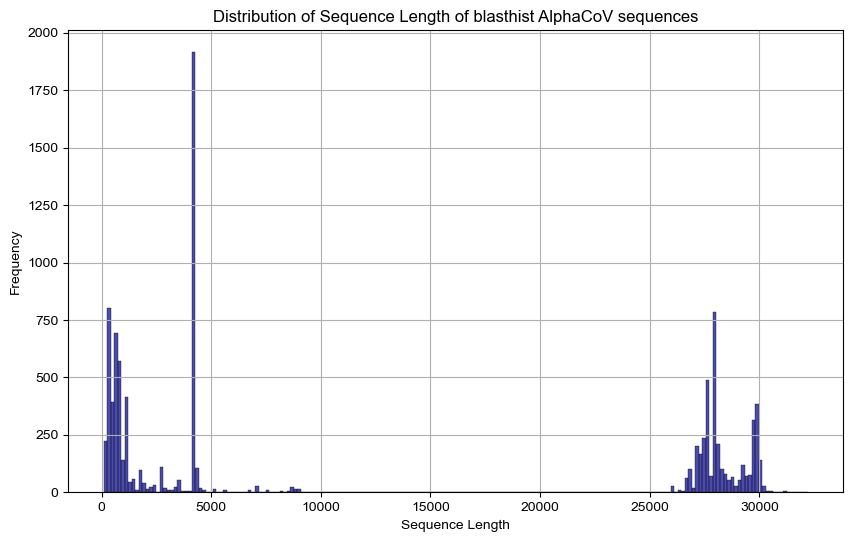

In [26]:
plt.figure(figsize=(10, 6))
sns.histplot(AlphaCoV_blast['seq_length'], bins=200, alpha=0.7, color='darkblue')
plt.title("Distribution of Sequence Length of blasthist AlphaCoV sequences")
plt.xlabel("Sequence Length")
plt.ylabel("Frequency")
plt.grid(True)
plt.show()

In [28]:
AlphaCoV_blast_filtered = AlphaCoV_blast[AlphaCoV_blast['seq_length'] >= 25000]
AlphaCoV_blast_filtered = AlphaCoV_blast_filtered[AlphaCoV_blast_filtered['N_count'] == 0]
AlphaCoV_blast_filtered

,ID,organism,host,location,collection_date,dataset,seq,seq_length,N_count
0,PV096984.1,Porcine respiratory coronavirus,pig,China,16-Dec-2024,blast,ACTTTTAAAGTAAAGTGAGTGTAGCGTGGCTATATCTCTTCTTTTA...,27904,0
1,OR209252.1,Porcine respiratory coronavirus,swine,USA,1991,blast,TTAAAGTAAAGTGAGTGTAGCGTGGCTATATCTCTTCTTTTACTTT...,27898,0
2,OR209251.1,Porcine respiratory coronavirus,swine,USA,1989,blast,GCTATATCTCTTCTTTTACTTTAACTAGCCTTGTGCTAGATTTTGT...,27869,0
3,OM830319.1,Porcine respiratory coronavirus 310,porcine,USA,01-Jun-1993,blast,GTGAGTGTAGCGTGGCTATATCTCTTCTTTTACTTTAACTAGCCTT...,27547,0
4,DQ811787.1,Porcine respiratory coronavirus ISU-1,pig,USA:Indiana,,blast,AAAGTGAGTGTAGCGTGGCTATATCTCTTATTTTACTTTAACTAGC...,27550,0
...,...,...,...,...,...,...,...,...,...
9806,PP845452.1,Bird gammacoronavirus NumeniusCN24,Numenius phaeopus,China: Shanghai,07-Sep-2022,blast,GCCTTGTGCAAGACTTTTTCCTTAACAAAACGGACTTAAAATACCC...,27382,0
9807,PP845451.1,Bird gammacoronavirus NumeniusCN24,Numenius phaeopus,China: Shanghai,07-Sep-2022,blast,GCCTTGTGCAAGACTTTTTCCTTAACAAAACGGACTTAAAATACCC...,27382,0
9809,PP845449.1,Bird gammacoronavirus NumeniusCN24,Numenius phaeopus,China: Shanghai,07-Sep-2022,blast,GCCTTGTGCAAGACTTTTTCCTTAACAAAACGGACTTAAAATACCC...,27382,0
9811,PQ577596.1,Alphacoronavirus sp.,Miniopterus pusillus,China,20-May-2013,blast,ATACTCAATCTACGGATAGAGTGTACTCTTTCTAGACTTTGGTCTA...,28426,0


In [29]:
with open('Alphacov1_ntblast_seq_cleaned_wg.fasta', 'w') as f:
    for index, row in AlphaCoV_blast_filtered.iterrows():
        f.write(f">{row['ID']}\n{row['seq']}\n")